## 유방암 악성 여부 예측

검체의 세포핵 측정값 30개로 악성 여부를 예측한다. 한 행은 검체 하나이며, 정답 `malignant`는 악성 1, 양성 종양 0이다.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import f1_score, log_loss
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree

SEED = 42
models = {}
model_results = {}


### 데이터 준비


In [2]:
cancer = load_breast_cancer(as_frame=True)
X = cancer.data.copy()
y = (cancer.target == 0).astype(int).rename("malignant")
feature_names = X.columns

print("입력과 정답:", X.shape, y.shape)
display(pd.concat([X, y], axis=1).head())
display(X.isna().sum().rename("missing_count"))


입력과 정답: (569, 30) (569,)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,malignant
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
Name: missing_count, dtype: int64

### 학습·검증·테스트 분리


In [3]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=SEED,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25, stratify=y_train_val, random_state=SEED,
)

display(pd.DataFrame([
    {"split": name, "rows": len(labels), "malignant_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
]))


,split,rows,malignant_rate
0,train,341,0.372434
1,validation,114,0.377193
2,test,114,0.368421


### 깊이 2의 결정 트리


In [4]:
tree_model = DecisionTreeClassifier(
    max_depth=2,
    min_samples_leaf=2,
    random_state=SEED,
)

tree_model.fit(X_train, y_train)

tree_val_prediction = tree_model.predict(X_val)

models["tree_depth2"] = tree_model

display(pd.DataFrame({
    "actual": y_val,
    "predicted": tree_val_prediction,
}).head())


,actual,predicted
488,0,0
212,1,1
175,0,0
482,0,0
361,0,0


### 트리의 분기 확인


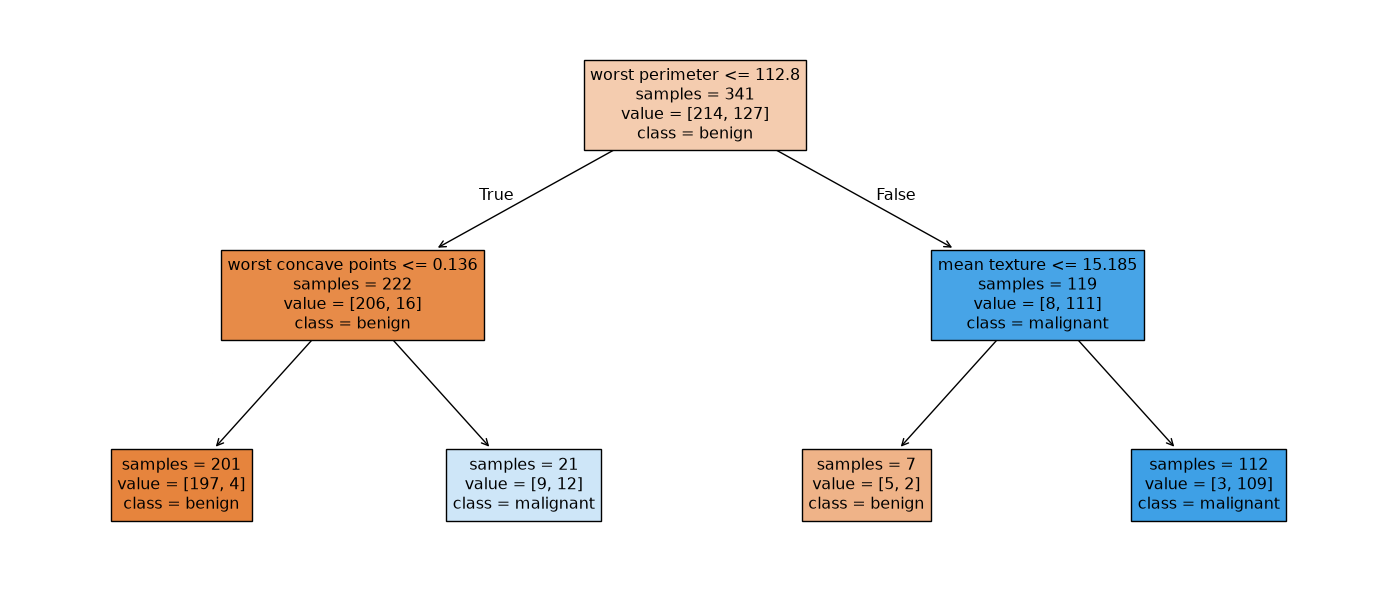

In [5]:
plt.figure(figsize=(14, 6))
plot_tree(
    tree_model, feature_names=feature_names,
    class_names=["benign", "malignant"], filled=True, impurity=False,
)
plt.tight_layout()
plt.show()


### 기본 모델 평가


In [6]:
name = "tree_depth2"
model = models[name]
train_prediction = model.predict(X_train)
val_prediction = model.predict(X_val)
train_f1 = f1_score(y_train, train_prediction, zero_division=0)
val_f1 = f1_score(y_val, val_prediction, zero_division=0)
model_results[name] = {
    "model": name,
    "train_f1": train_f1,
    "val_f1": val_f1,
}

model_comparison = pd.DataFrame(model_results.values())
display(model_comparison)


,model,train_f1,val_f1
0,tree_depth2,0.930769,0.857143


## 추가 실험

### 결정 트리의 깊이 비교

최대 깊이를 2·3·5·제한 없음으로 바꾸고, 최소 잎 사례 수는 2로 유지한다. 학습·검증 F1과 실제 깊이·잎 수를 비교한다.


In [7]:
TREE_DEPTHS = [2, 3, 5, None]
depth_rows = []
for depth in TREE_DEPTHS:
    name = f"tree_depth{depth}" if depth is not None else "tree_unlimited"
    model = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=2, random_state=SEED,
    )
    model.fit(X_train, y_train)
    models[name] = model
    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)
    train_f1 = f1_score(y_train, train_prediction, zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, zero_division=0)
    model_results[name] = {
        "model": name,
        "train_f1": train_f1,
        "val_f1": val_f1,
    }
    depth_rows.append({
        **model_results[name],
        "actual_depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
    })

depth_comparison = pd.DataFrame(depth_rows)
display(depth_comparison)


,model,train_f1,val_f1,actual_depth,leaves
0,tree_depth2,0.930769,0.857143,2,4
1,tree_depth3,0.976190,0.894118,3,8
2,tree_depth5,0.976190,0.894118,5,12
3,tree_unlimited,0.976190,0.906977,6,13


### 깊이별 학습·검증 F1


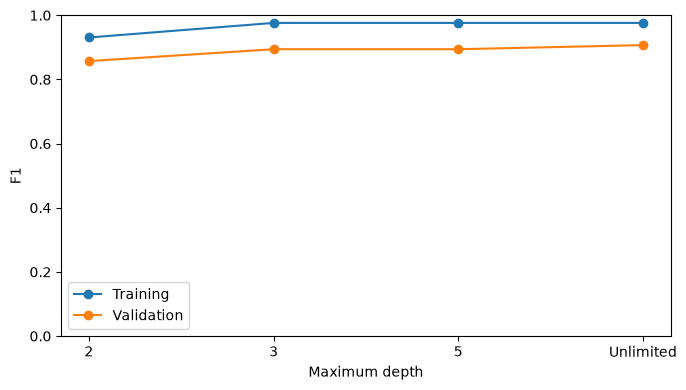

In [8]:
depth_labels = [str(depth) if depth is not None else "Unlimited" for depth in TREE_DEPTHS]
plt.figure(figsize=(7, 4))
plt.plot(depth_labels, depth_comparison["train_f1"], marker="o", label="Training")
plt.plot(depth_labels, depth_comparison["val_f1"], marker="o", label="Validation")
plt.xlabel("Maximum depth")
plt.ylabel("F1")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.show()


### 랜덤포레스트의 트리 수 비교

트리 수를 1·50·100개로 바꾸고, 최대 깊이 5와 최소 잎 사례 수 2는 유지한다. 깊이 5인 단일 결정 트리와 함께 비교한다.


In [9]:
FOREST_TREE_COUNTS = [1, 50, 100]
forest_rows = [model_results["tree_depth5"]]
for tree_count in FOREST_TREE_COUNTS:
    name = f"forest_{tree_count}"
    model = RandomForestClassifier(
        n_estimators=tree_count,
        max_depth=5, min_samples_leaf=2,
        max_features="sqrt",
        bootstrap=True,
        random_state=SEED,
        n_jobs=1,
    )
    model.fit(X_train, y_train)
    models[name] = model
    train_prediction = model.predict(X_train)
    val_prediction = model.predict(X_val)
    train_f1 = f1_score(y_train, train_prediction, zero_division=0)
    val_f1 = f1_score(y_val, val_prediction, zero_division=0)
    model_results[name] = {
        "model": name,
        "train_f1": train_f1,
        "val_f1": val_f1,
    }
    forest_rows.append(model_results[name])

forest_comparison = pd.DataFrame(forest_rows)
display(forest_comparison)


,model,train_f1,val_f1
0,tree_depth5,0.976190,0.894118
1,forest_1,0.939271,0.965517
2,forest_50,0.992063,0.964706
3,forest_100,0.992063,0.964706


### Gradient Boosting의 학습률과 트리 수 비교

학습률 0.05·0.1과 트리 수 30·100·200을 조합한다. 각 트리의 최대 깊이는 2, 최소 잎 사례 수는 2로 유지한다.


In [10]:
BOOSTING_LEARNING_RATES = [0.05, 0.1]
BOOSTING_TREE_COUNTS = [30, 100, 200]
boosting_rows = []
for learning_rate in BOOSTING_LEARNING_RATES:
    for tree_count in BOOSTING_TREE_COUNTS:
        name = f"boost_lr{learning_rate}_trees{tree_count}"
        model = GradientBoostingClassifier(
            n_estimators=tree_count,
            learning_rate=learning_rate,
            max_depth=2, min_samples_leaf=2, random_state=SEED,
        )
        model.fit(X_train, y_train)
        models[name] = model
        train_prediction = model.predict(X_train)
        val_prediction = model.predict(X_val)
        train_f1 = f1_score(y_train, train_prediction, zero_division=0)
        val_f1 = f1_score(y_val, val_prediction, zero_division=0)
        model_results[name] = {
            "model": name,
            "train_f1": train_f1,
            "val_f1": val_f1,
        }
        boosting_rows.append(model_results[name])

boosting_comparison = pd.DataFrame(boosting_rows)
display(boosting_comparison)


,model,train_f1,val_f1
0,boost_lr0.05_trees30,0.968504,0.911111
1,boost_lr0.05_trees100,0.992063,0.931818
2,boost_lr0.05_trees200,1.000000,0.931818
3,boost_lr0.1_trees30,0.992063,0.942529
4,boost_lr0.1_trees100,1.000000,0.931818
5,boost_lr0.1_trees200,1.000000,0.942529


### 단계별 학습·검증 손실

학습률별로 트리 200개를 학습한 모델의 로그 손실을 비교한다. 점선은 검증 로그 손실이 가장 낮은 단계다.


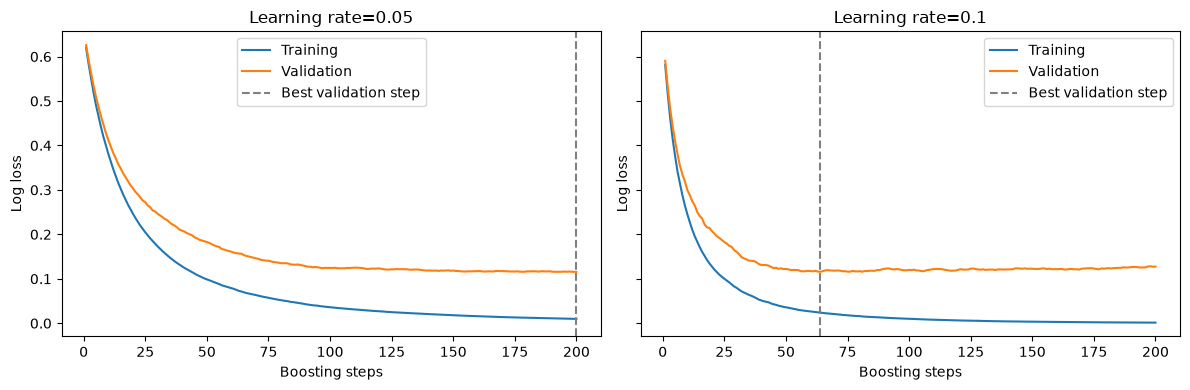

,learning_rate,best_step,best_val_loss,last_val_loss
0,0.05,200,0.115297,0.115297
1,0.10,64,0.115757,0.127461


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
loss_rows = []
for ax, rate in zip(axes, BOOSTING_LEARNING_RATES):
    curve_model = models[f"boost_lr{rate}_trees200"]
    train_loss = [log_loss(y_train, probabilities) for probabilities in
                  curve_model.staged_predict_proba(X_train)]
    val_loss = [log_loss(y_val, probabilities) for probabilities in
                curve_model.staged_predict_proba(X_val)]
    steps = np.arange(1, len(train_loss) + 1)
    best_step = int(np.argmin(val_loss)) + 1
    ax.plot(steps, train_loss, label="Training")
    ax.plot(steps, val_loss, label="Validation")
    ax.axvline(best_step, color="gray", linestyle="--", label="Best validation step")
    ax.set(title=f"Learning rate={rate}", xlabel="Boosting steps", ylabel="Log loss")
    ax.legend()
    loss_rows.append({
        "learning_rate": rate, "best_step": best_step,
        "best_val_loss": min(val_loss), "last_val_loss": val_loss[-1],
    })
plt.tight_layout()
plt.show()
display(pd.DataFrame(loss_rows))


### 보정 트리의 깊이 비교

학습률 0.1, 트리 수 100, 최소 잎 사례 수 2를 유지하고 최대 깊이를 2에서 3으로 바꾼다.


In [12]:
deeper_boosting_model = GradientBoostingClassifier(
    n_estimators=100, learning_rate=0.1,
    max_depth=3, min_samples_leaf=2, random_state=SEED,
)
deeper_boosting_model.fit(X_train, y_train)
models["boost_depth3"] = deeper_boosting_model

name = "boost_depth3"
model = deeper_boosting_model
train_prediction = model.predict(X_train)
val_prediction = model.predict(X_val)
train_f1 = f1_score(y_train, train_prediction, zero_division=0)
val_f1 = f1_score(y_val, val_prediction, zero_division=0)
model_results[name] = {
    "model": name,
    "train_f1": train_f1,
    "val_f1": val_f1,
}

display(pd.DataFrame([
    model_results["boost_lr0.1_trees100"],
    model_results["boost_depth3"],
]))


,model,train_f1,val_f1
0,boost_lr0.1_trees100,1.0,0.931818
1,boost_depth3,1.0,0.953488


### 최종 모델 선택

검증 F1이 가장 높은 모델을 선택하고, 동점이면 먼저 등록한 후보를 사용한다.

실행 결과, 트리 1개인 `forest_1`의 검증 F1이 약 0.966으로 가장 높다. 트리 50개·100개인 모델의 검증 F1은 약 0.965로 차이가 작다. 이 분할에서는 트리 수를 늘렸을 때 학습 F1은 높아졌고 검증 F1은 비슷했다. 정한 선택 기준에 따라 `forest_1`을 사용한다.

다른 계열에서 검증 F1이 가장 높은 `boost_depth3`은 학습 F1이 1.000, 검증 F1이 약 0.953이다. 선택한 `forest_1`은 학습 F1이 약 0.939, 검증 F1이 약 0.966으로, 이번 비교에서는 학습 점수가 더 낮고 검증 점수가 더 높다.


In [13]:
model_comparison = pd.DataFrame(model_results.values())
model_comparison = model_comparison.sort_values(
    "val_f1", ascending=False, kind="stable",
)
display(model_comparison)
selected_name = model_comparison.iloc[0]["model"]
selected_model = models[selected_name]
print("선택한 모델:", selected_name)


,model,train_f1,val_f1
4,forest_1,0.939271,0.965517
5,forest_50,0.992063,0.964706
6,forest_100,0.992063,0.964706
13,boost_depth3,1.000000,0.953488
10,boost_lr0.1_trees30,0.992063,0.942529
12,boost_lr0.1_trees200,1.000000,0.942529
8,boost_lr0.05_trees100,0.992063,0.931818
9,boost_lr0.05_trees200,1.000000,0.931818
11,boost_lr0.1_trees100,1.000000,0.931818
7,boost_lr0.05_trees30,0.968504,0.911111


선택한 모델: forest_1


### 최종 테스트


In [14]:
final_train_prediction = selected_model.predict(X_train)
test_prediction = selected_model.predict(X_test)

final_rows = []
for split, actual, prediction in [
    ("train", y_train, final_train_prediction),
    ("test", y_test, test_prediction),
]:
    final_rows.append({
        "split": split,
        "F1": f1_score(actual, prediction, zero_division=0),
    })
final_comparison = pd.DataFrame(final_rows)
print("선택 모델:", selected_name)
display(final_comparison)


선택 모델: forest_1


,split,F1
0,train,0.939271
1,test,0.868421
